In [1]:

import pandas as pd
from google.colab import files

# Upload the CSV file you downloaded from RBI
uploaded = files.upload()

filename = next(iter(uploaded))

# Load the dataset
df = pd.read_csv(filename)

# Inspect the data
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()


Saving r691_daily_interbank_forex_rates_usd_vis_a_vis_inr.csv to r691_daily_interbank_forex_rates_usd_vis_a_vis_inr.csv
Dataset shape: (6319, 10)

Column names:
['src_file', 'tab', 'period', 'row_no', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6']

First five rows:


,src_file,tab,period,row_no,c1,c2,c3,c4,c5,c6
0,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,1,NaN,NaN,NaN,NaN,NaN,NaN
1,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,2,Source : Reserve Bank Of India,NaN,NaN,NaN,NaN,NaN
2,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,3,NaN,NaN,NaN,NaN,NaN,NaN
3,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,4,Forex Rates (United States Dollars),NaN,NaN,NaN,NaN,NaN
4,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,5,NaN,NaN,NaN,NaN,NaN,NaN



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6319 entries, 0 to 6318
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   src_file  6319 non-null   object
 1   tab       6319 non-null   object
 2   period    6319 non-null   object
 3   row_no    6319 non-null   int64 
 4   c1        6313 non-null   object
 5   c2        6309 non-null   object
 6   c3        6309 non-null   object
 7   c4        6309 non-null   object
 8   c5        6309 non-null   object
 9   c6        6309 non-null   object
dtypes: int64(1), object(9)
memory usage: 493.8+ KB


In [2]:

# Display rows around the table header and the beginning of the data
pd.set_option("display.max_rows", 35)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

display(df[["row_no", "c1", "c2", "c3", "c4", "c5", "c6"]].head(35))


,row_no,c1,c2,c3,c4,c5,c6
0,1,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Source : Reserve Bank Of India,NaN,NaN,NaN,NaN,NaN
2,3,NaN,NaN,NaN,NaN,NaN,NaN
3,4,Forex Rates (United States Dollars),NaN,NaN,NaN,NaN,NaN
4,5,NaN,NaN,NaN,NaN,NaN,NaN
5,6,Data available from August 2000,NaN,NaN,NaN,NaN,NaN
6,7,NaN,NaN,NaN,NaN,NaN,NaN
7,8,Figures in Rs.\r\n,NaN,NaN,NaN,NaN,NaN
8,9,NaN,NaN,NaN,NaN,NaN,NaN
9,10,Date,Interbank Open Rate,Interbank High Rate,Interbank Low Rate,Interbank Close Rate,RBI Reference Rate


Clean dataset shape: (6101, 6)
Date range: 2000-08-08 00:00:00 to 2026-06-30 00:00:00

First five observations:


,Date,Open,High,Low,Close,RBI_Reference_Rate
0,2000-08-08,45.565,45.565,45.7325,45.730,45.72
1,2000-08-09,45.770,45.530,45.7700,45.615,45.64
2,2000-08-10,45.650,45.615,45.8400,45.840,45.68
3,2000-08-11,45.900,45.800,46.0500,45.820,45.93
4,2000-08-14,45.680,45.680,45.9050,45.725,45.77



Last five observations:


,Date,Open,High,Low,Close,RBI_Reference_Rate
6096,2026-06-23,94.705,94.635,94.925,94.735,94.7064
6097,2026-06-24,94.905,94.595,94.935,94.665,94.6980
6098,2026-06-25,94.315,94.135,94.565,94.405,94.4804
6099,2026-06-29,94.365,94.245,94.565,94.545,94.3519
6100,2026-06-30,94.575,94.515,94.765,94.675,94.5975


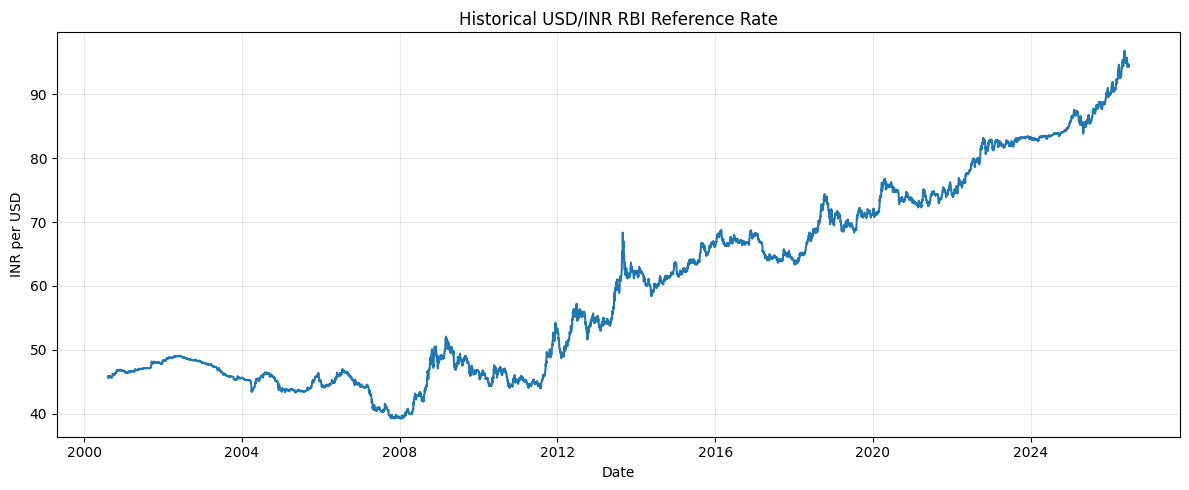

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract the actual table, skipping report metadata
clean_df = df.loc[df["c1"].astype(str).str.strip().str.match(
    r"\d{1,2}\s+[A-Za-z]+\s+\d{4}", na=False
), ["c1", "c2", "c3", "c4", "c5", "c6"]].copy()

# Rename columns
clean_df.columns = [
    "Date",
    "Open",
    "High",
    "Low",
    "Close",
    "RBI_Reference_Rate"
]

# Convert data types
clean_df["Date"] = pd.to_datetime(
    clean_df["Date"], format="%d %B %Y", errors="coerce"
)

rate_columns = ["Open", "High", "Low", "Close", "RBI_Reference_Rate"]

for col in rate_columns:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

# Remove invalid rows, sort oldest to newest
clean_df = (
    clean_df.dropna()
    .drop_duplicates(subset="Date")
    .sort_values("Date")
    .reset_index(drop=True)
)

print("Clean dataset shape:", clean_df.shape)
print("Date range:", clean_df["Date"].min(), "to", clean_df["Date"].max())
print("\nFirst five observations:")
display(clean_df.head())

print("\nLast five observations:")
display(clean_df.tail())

# Plot the historical reference rate
plt.figure(figsize=(12, 5))
plt.plot(clean_df["Date"], clean_df["RBI_Reference_Rate"])
plt.title("Historical USD/INR RBI Reference Rate")
plt.xlabel("Date")
plt.ylabel("INR per USD")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Save a clean copy
clean_df.to_csv("clean_usd_inr.csv", index=False)


In [4]:

import numpy as np

# Keep the reference rate and date
model_df = clean_df[["Date", "RBI_Reference_Rate"]].copy()

# Use past rates to predict the next available rate
model_df["Rate_Lag_1"] = model_df["RBI_Reference_Rate"].shift(1)
model_df["Rate_Lag_2"] = model_df["RBI_Reference_Rate"].shift(2)
model_df["Rate_Lag_5"] = model_df["RBI_Reference_Rate"].shift(5)

# Recent moving averages, using only past observations
model_df["Mean_Last_5"] = (
    model_df["RBI_Reference_Rate"].shift(1).rolling(5).mean()
)
model_df["Mean_Last_20"] = (
    model_df["RBI_Reference_Rate"].shift(1).rolling(20).mean()
)

# Today's target is the next available observation's rate
model_df["Target"] = model_df["RBI_Reference_Rate"].shift(-1)

# Remove rows without enough historical information
model_df = model_df.dropna().reset_index(drop=True)

features = [
    "Rate_Lag_1",
    "Rate_Lag_2",
    "Rate_Lag_5",
    "Mean_Last_5",
    "Mean_Last_20"
]

X = model_df[features]
y = model_df["Target"]

print("Number of observations:", len(model_df))
print("\nFeatures:")
display(X.head())

print("\nTarget values:")
display(y.head())


Number of observations: 6080

Features:


,Rate_Lag_1,Rate_Lag_2,Rate_Lag_5,Mean_Last_5,Mean_Last_20
0,45.64,45.68,45.80,45.718,45.7685
1,45.64,45.64,45.73,45.686,45.7645
2,45.63,45.64,45.74,45.666,45.7640
3,45.60,45.63,45.68,45.638,45.7600
4,45.64,45.60,45.64,45.630,45.7455



Target values:


,Target
0,45.63
1,45.60
2,45.64
3,45.68
4,45.76


RANDOM FOREST MODEL
MAE:  7.1620 INR
RMSE: 8.6260 INR

NAIVE BASELINE
MAE:  0.2137 INR
RMSE: 0.3141 INR


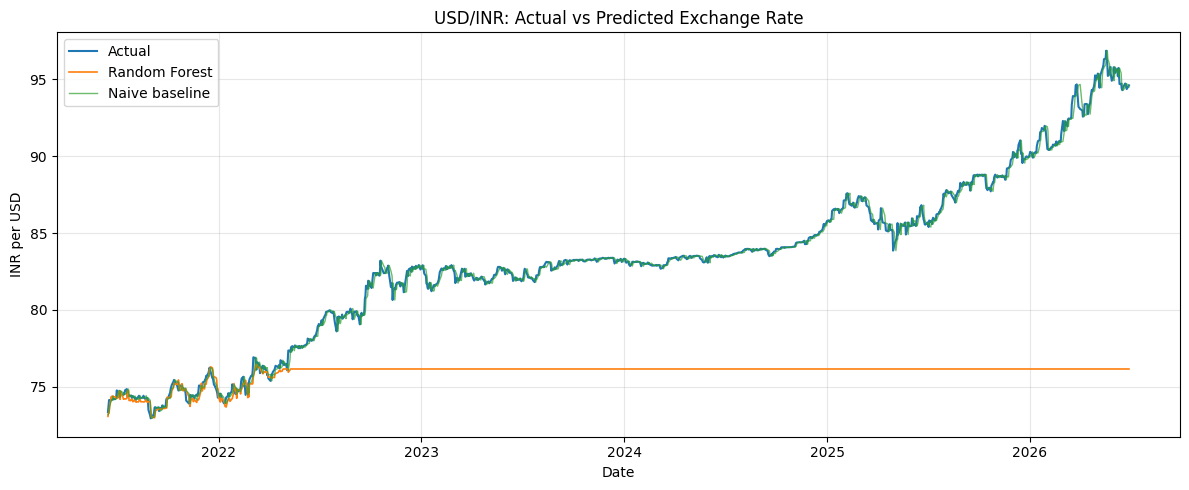

In [5]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import numpy as np

# Chronological train-test split
split = int(len(model_df) * 0.80)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

# Train the model
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Generate predictions on unseen test observations
predictions = model.predict(X_test)

# Simple benchmark: next rate equals the latest known rate
baseline_predictions = X_test["Rate_Lag_1"].to_numpy()

# Evaluate both methods
mae_ml = mean_absolute_error(y_test, predictions)
rmse_ml = np.sqrt(mean_squared_error(y_test, predictions))

mae_baseline = mean_absolute_error(y_test, baseline_predictions)
rmse_baseline = np.sqrt(mean_squared_error(y_test, baseline_predictions))

print("RANDOM FOREST MODEL")
print(f"MAE:  {mae_ml:.4f} INR")
print(f"RMSE: {rmse_ml:.4f} INR")

print("\nNAIVE BASELINE")
print(f"MAE:  {mae_baseline:.4f} INR")
print(f"RMSE: {rmse_baseline:.4f} INR")

# Plot actual vs predicted rates
plt.figure(figsize=(12, 5))
plt.plot(model_df["Date"].iloc[split:], y_test.values,
         label="Actual", linewidth=1.5)
plt.plot(model_df["Date"].iloc[split:], predictions,
         label="Random Forest", linewidth=1.2)
plt.plot(model_df["Date"].iloc[split:], baseline_predictions,
         label="Naive baseline", linewidth=1, alpha=0.7)

plt.title("USD/INR: Actual vs Predicted Exchange Rate")
plt.xlabel("Date")
plt.ylabel("INR per USD")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


RECENT-PERIOD RANDOM FOREST
MAE:  0.3335 INR
RMSE: 0.4437 INR

NAIVE BASELINE
MAE:  0.3197 INR
RMSE: 0.4335 INR


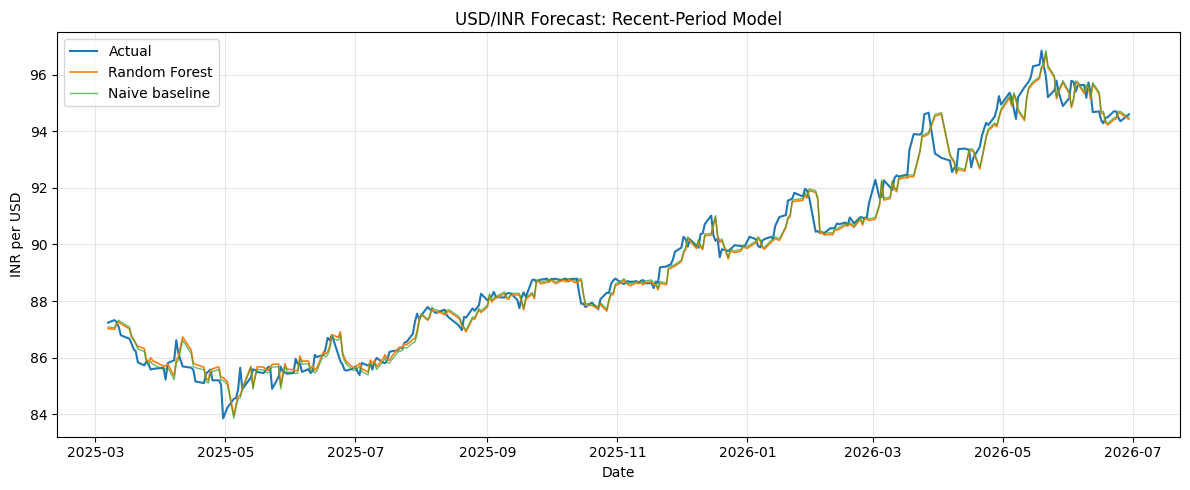

In [6]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import numpy as np

# Focus on the recent exchange-rate period
recent_df = model_df.loc[
    model_df["Date"] >= "2020-01-01"
].copy().reset_index(drop=True)

# Predict the next observation's change, not its absolute rate
recent_df["Target_Change"] = (
    recent_df["Target"] - recent_df["Rate_Lag_1"]
)

X_recent = recent_df[features]
y_change = recent_df["Target_Change"]

# Keep the data in chronological order
split_recent = int(len(recent_df) * 0.80)

X_train_r = X_recent.iloc[:split_recent]
X_test_r = X_recent.iloc[split_recent:]

y_train_r = y_change.iloc[:split_recent]
y_test_r = y_change.iloc[split_recent:]

# Train Random Forest on exchange-rate changes
model_change = RandomForestRegressor(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

model_change.fit(X_train_r, y_train_r)

# Convert predicted changes back into exchange-rate levels
predicted_changes = model_change.predict(X_test_r)

rf_rates = (
    X_test_r["Rate_Lag_1"].to_numpy() + predicted_changes
)

# Naive benchmark: no change from the latest known rate
baseline_rates = X_test_r["Rate_Lag_1"].to_numpy()

actual_rates = recent_df["Target"].iloc[split_recent:].to_numpy()
test_dates = recent_df["Date"].iloc[split_recent:]

# Evaluate
print("RECENT-PERIOD RANDOM FOREST")
print(f"MAE:  {mean_absolute_error(actual_rates, rf_rates):.4f} INR")
print(f"RMSE: {np.sqrt(mean_squared_error(actual_rates, rf_rates)):.4f} INR")

print("\nNAIVE BASELINE")
print(f"MAE:  {mean_absolute_error(actual_rates, baseline_rates):.4f} INR")
print(f"RMSE: {np.sqrt(mean_squared_error(actual_rates, baseline_rates)):.4f} INR")

# Compare forecasts
plt.figure(figsize=(12, 5))
plt.plot(test_dates, actual_rates, label="Actual", linewidth=1.5)
plt.plot(test_dates, rf_rates, label="Random Forest", linewidth=1.2)
plt.plot(test_dates, baseline_rates, label="Naive baseline",
         linewidth=1, alpha=0.7)

plt.title("USD/INR Forecast: Recent-Period Model")
plt.xlabel("Date")
plt.ylabel("INR per USD")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


,Model,MAE,RMSE
0,Random Forest,2.8030,3.9650
1,Naive baseline,0.2171,0.3074


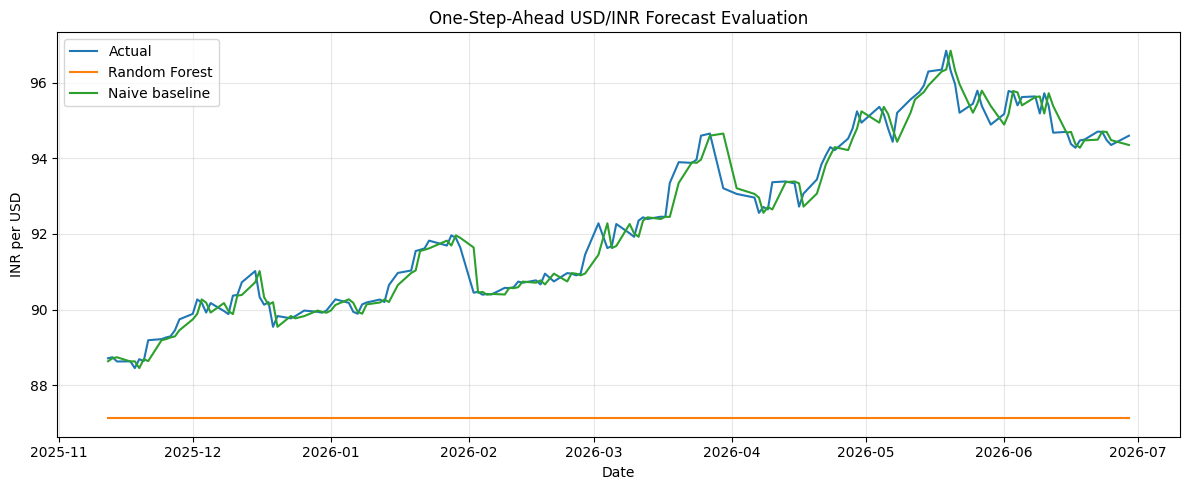

In [7]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Start from the cleaned historical data
forecast_df = clean_df[["Date", "RBI_Reference_Rate"]].copy()
forecast_df = forecast_df.sort_values("Date").reset_index(drop=True)

rate = forecast_df["RBI_Reference_Rate"]

# Features available at the end of observation t
forecast_df["Rate_Lag_1"] = rate
forecast_df["Rate_Lag_2"] = rate.shift(1)
forecast_df["Rate_Lag_5"] = rate.shift(4)
forecast_df["Mean_Last_5"] = rate.rolling(5).mean()
forecast_df["Mean_Last_20"] = rate.rolling(20).mean()

# Predict the next available observation, t+1
forecast_df["Target"] = rate.shift(-1)

features = [
    "Rate_Lag_1",
    "Rate_Lag_2",
    "Rate_Lag_5",
    "Mean_Last_5",
    "Mean_Last_20"
]

forecast_df = forecast_df.dropna().reset_index(drop=True)

# Focus on observations from 2020 onwards
forecast_df = forecast_df[
    forecast_df["Date"] >= "2020-01-01"
].reset_index(drop=True)

X = forecast_df[features]
y = forecast_df["Target"]

# Chronological 80/20 split
split = int(len(forecast_df) * 0.80)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Train the corrected one-step-ahead model
final_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)
rf_predictions = final_model.predict(X_test)

# Baseline: next rate equals the latest observed rate
baseline_predictions = X_test["Rate_Lag_1"].to_numpy()

results = pd.DataFrame({
    "Model": ["Random Forest", "Naive baseline"],
    "MAE": [
        mean_absolute_error(y_test, rf_predictions),
        mean_absolute_error(y_test, baseline_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, rf_predictions)),
        np.sqrt(mean_squared_error(y_test, baseline_predictions))
    ]
})

display(results.round(4))

# Visualise the last 150 test observations
n = min(150, len(y_test))

plt.figure(figsize=(12, 5))
plt.plot(forecast_df["Date"].iloc[split:].tail(n),
         y_test.tail(n), label="Actual")
plt.plot(forecast_df["Date"].iloc[split:].tail(n),
         rf_predictions[-n:], label="Random Forest")
plt.plot(forecast_df["Date"].iloc[split:].tail(n),
         baseline_predictions[-n:], label="Naive baseline")

plt.title("One-Step-Ahead USD/INR Forecast Evaluation")
plt.xlabel("Date")
plt.ylabel("INR per USD")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:

# The latest actual observation and its date
latest_date = clean_df["Date"].iloc[-1]
latest_rate = clean_df["RBI_Reference_Rate"].iloc[-1]

# Build the feature row from the latest available observations
rates = clean_df["RBI_Reference_Rate"]

latest_features = pd.DataFrame([{
    "Rate_Lag_1": rates.iloc[-1],
    "Rate_Lag_2": rates.iloc[-2],
    "Rate_Lag_5": rates.iloc[-5],
    "Mean_Last_5": rates.iloc[-5:].mean(),
    "Mean_Last_20": rates.iloc[-20:].mean()
}])[features]

# Generate both forecasts
rf_forecast = final_model.predict(latest_features)[0]
baseline_forecast = latest_rate

print("USD/INR FORECAST")
print("-" * 35)
print("Latest observed date:", latest_date.strftime("%d %B %Y"))
print(f"Latest observed rate: ₹{latest_rate:.4f} per USD")
print(f"Random Forest forecast: ₹{rf_forecast:.4f} per USD")
print(f"Naive baseline forecast: ₹{baseline_forecast:.4f} per USD")
print(f"RF predicted change: ₹{rf_forecast - latest_rate:+.4f} per USD")
print("\nForecast horizon: Next available observation")
print("This is an experimental model output, not financial advice.")


USD/INR FORECAST
-----------------------------------
Latest observed date: 30 June 2026
Latest observed rate: ₹94.5975 per USD
Random Forest forecast: ₹87.1274 per USD
Naive baseline forecast: ₹94.5975 per USD
RF predicted change: ₹-7.4701 per USD

Forecast horizon: Next available observation
This is an experimental model output, not financial advice.


In [9]:

print("TRAINING DATA")
print("Date range:",
      forecast_df["Date"].iloc[:split].min(),
      "to",
      forecast_df["Date"].iloc[:split].max())

print("Training target range:",
      round(y_train.min(), 4),
      "to",
      round(y_train.max(), 4))

print("\nTEST DATA")
print("Test feature rate range:",
      round(X_test["Rate_Lag_1"].min(), 4),
      "to",
      round(X_test["Rate_Lag_1"].max(), 4))

print("Actual test target range:",
      round(y_test.min(), 4),
      "to",
      round(y_test.max(), 4))

print("\nPREDICTION CHECK")
print("Random Forest prediction range:",
      round(rf_predictions.min(), 4),
      "to",
      round(rf_predictions.max(), 4))

print("\nFEATURE IMPORTANCE")
importance = pd.Series(
    final_model.feature_importances_,
    index=features
).sort_values(ascending=False)

display(importance.to_frame("Importance").round(4))


TRAINING DATA
Date range: 2020-01-01 00:00:00 to 2025-03-06 00:00:00
Training target range: 70.8115 to 87.5858

TEST DATA
Test feature rate range: 83.8568 to 96.8441
Actual test target range: 83.8568 to 96.8441

PREDICTION CHECK
Random Forest prediction range: 84.837 to 87.1274

FEATURE IMPORTANCE


,Importance
Mean_Last_20,0.2609
Mean_Last_5,0.2466
Rate_Lag_1,0.2269
Rate_Lag_2,0.1474
Rate_Lag_5,0.1182


In [11]:

# Rebuild the dataset with correctly aligned one-step-ahead features
deploy_df = clean_df[["Date", "RBI_Reference_Rate"]].copy()
deploy_df = deploy_df.sort_values("Date").reset_index(drop=True)

rate = deploy_df["RBI_Reference_Rate"]

deploy_df["Rate_Lag_1"] = rate
deploy_df["Rate_Lag_2"] = rate.shift(1)
deploy_df["Rate_Lag_5"] = rate.shift(4)
deploy_df["Mean_Last_5"] = rate.rolling(5).mean()
deploy_df["Mean_Last_20"] = rate.rolling(20).mean()
deploy_df["Target"] = rate.shift(-1)

features = [
    "Rate_Lag_1",
    "Rate_Lag_2",
    "Rate_Lag_5",
    "Mean_Last_5",
    "Mean_Last_20"
]

# Training data: 2020 onwards, excluding the final row
# because its next-observation target is not yet available
train_df = deploy_df[
    (deploy_df["Date"] >= "2020-01-01") &
    deploy_df["Target"].notna()
].dropna().copy()

X_all = train_df[features]
y_all = train_df["Target"]

deployment_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

deployment_model.fit(X_all, y_all)

# Build features using the latest actual observation
latest_features = pd.DataFrame([{
    "Rate_Lag_1": rate.iloc[-1],
    "Rate_Lag_2": rate.iloc[-2],
    "Rate_Lag_5": rate.iloc[-5],
    "Mean_Last_5": rate.iloc[-5:].mean(),
    "Mean_Last_20": rate.iloc[-20:].mean()
}])[features]

latest_rate = rate.iloc[-1]
latest_date = deploy_df["Date"].iloc[-1]

rf_forecast = deployment_model.predict(latest_features)[0]
baseline_forecast = latest_rate

print("FINAL FORECAST DEMONSTRATION")
print("=" * 40)
print("Training observations:", len(train_df))
print("Training ends:", train_df["Date"].max().date())
print("Latest actual date:", latest_date.date())
print(f"Latest observed rate: ₹{latest_rate:.4f}")
print(f"Random Forest forecast: ₹{rf_forecast:.4f}")
print(f"Naive baseline forecast: ₹{baseline_forecast:.4f}")
print(f"RF predicted change: ₹{rf_forecast - latest_rate:+.4f}")


FINAL FORECAST DEMONSTRATION
Training observations: 1562
Training ends: 2026-06-29
Latest actual date: 2026-06-30
Latest observed rate: ₹94.5975
Random Forest forecast: ₹94.4970
Naive baseline forecast: ₹94.5975
RF predicted change: ₹-0.1005


,Measure,Value
0,Latest observed date,30 June 2026
1,Latest observed rate,₹94.5975
2,Random Forest forecast,₹94.4970
3,Naive baseline forecast,₹94.5975
4,Predicted change,₹-0.1005


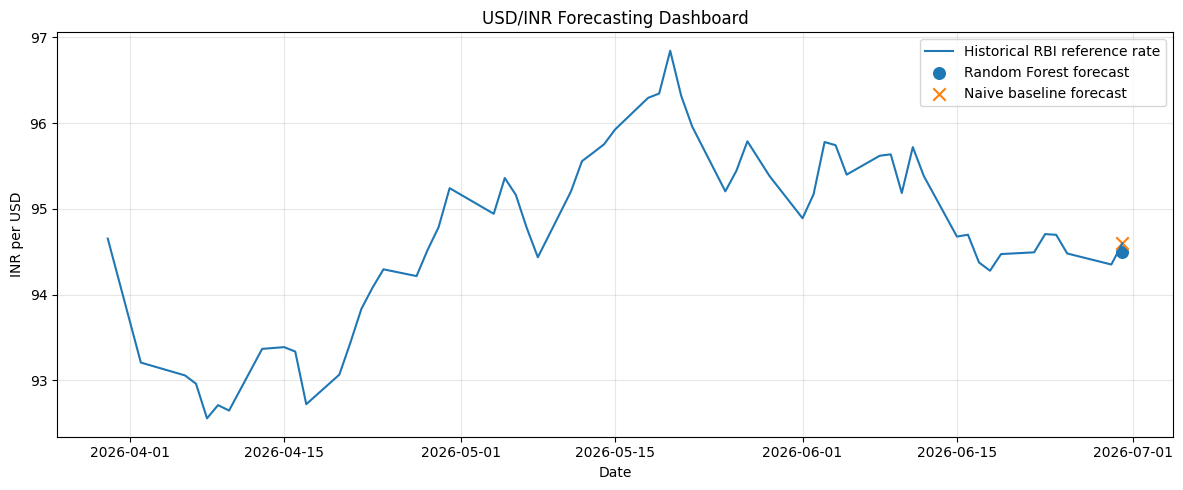

Cleaned dataset saved as clean_usd_inr.csv


In [12]:

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Create a clean summary of the forecast
forecast_summary = pd.DataFrame({
    "Measure": [
        "Latest observed date",
        "Latest observed rate",
        "Random Forest forecast",
        "Naive baseline forecast",
        "Predicted change"
    ],
    "Value": [
        latest_date.strftime("%d %B %Y"),
        f"₹{latest_rate:.4f}",
        f"₹{rf_forecast:.4f}",
        f"₹{baseline_forecast:.4f}",
        f"₹{rf_forecast - latest_rate:+.4f}"
    ]
})

display(forecast_summary)

# Plot recent history and the next-observation predictions
history = clean_df.tail(60)

plt.figure(figsize=(12, 5))
plt.plot(
    history["Date"],
    history["RBI_Reference_Rate"],
    label="Historical RBI reference rate"
)

plt.scatter(
    [latest_date],
    [rf_forecast],
    label="Random Forest forecast",
    marker="o",
    s=70
)

plt.scatter(
    [latest_date],
    [baseline_forecast],
    label="Naive baseline forecast",
    marker="x",
    s=80
)

plt.title("USD/INR Forecasting Dashboard")
plt.xlabel("Date")
plt.ylabel("INR per USD")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Save the cleaned dataset
clean_df.to_csv("clean_usd_inr.csv", index=False)

print("Cleaned dataset saved as clean_usd_inr.csv")


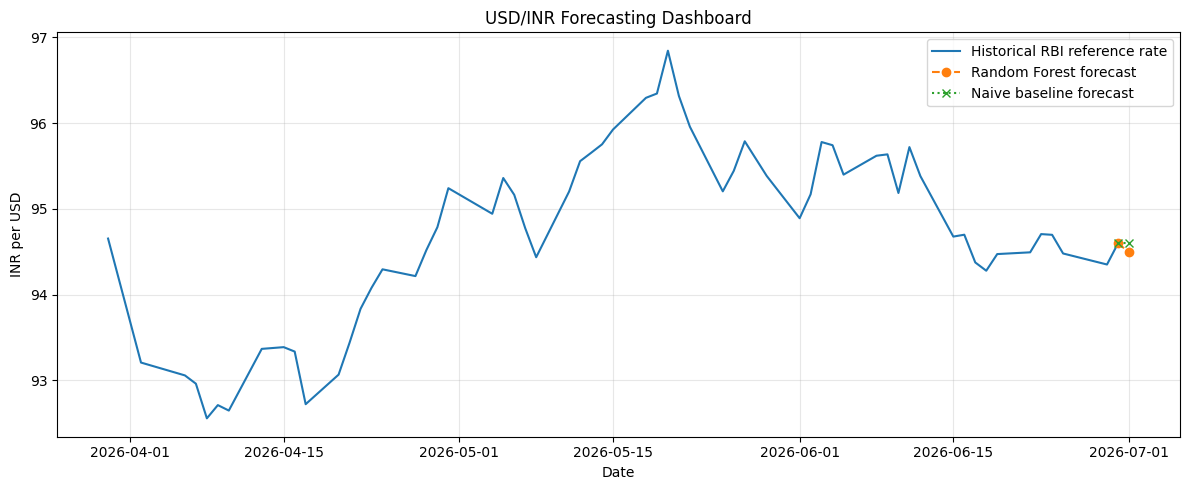

In [13]:

import pandas as pd
import matplotlib.pyplot as plt

history = clean_df.tail(60).copy()

# Use the next calendar day as a visual placeholder.
# The actual next trading date is not known from this dataset.
forecast_plot_date = latest_date + pd.Timedelta(days=1)

plt.figure(figsize=(12, 5))

plt.plot(
    history["Date"],
    history["RBI_Reference_Rate"],
    label="Historical RBI reference rate"
)

plt.plot(
    [latest_date, forecast_plot_date],
    [latest_rate, rf_forecast],
    marker="o",
    linestyle="--",
    label="Random Forest forecast"
)

plt.plot(
    [latest_date, forecast_plot_date],
    [latest_rate, baseline_forecast],
    marker="x",
    linestyle=":",
    label="Naive baseline forecast"
)

plt.title("USD/INR Forecasting Dashboard")
plt.xlabel("Date")
plt.ylabel("INR per USD")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


FINAL HOLDOUT MODEL COMPARISON


,Model,MAE,RMSE
0,Random Forest,2.8030,3.9650
1,Naive Baseline,0.2171,0.3074


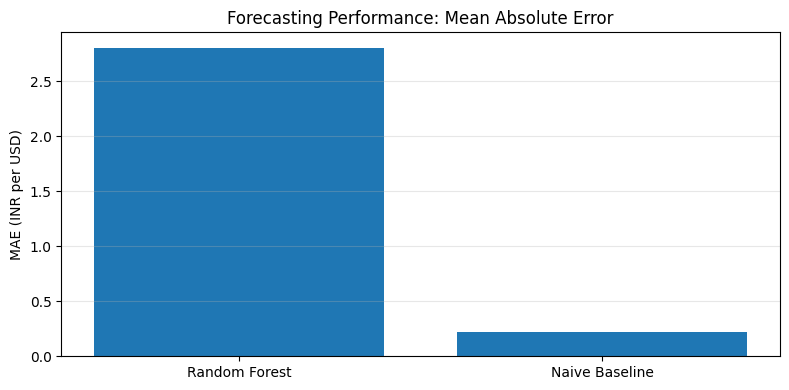

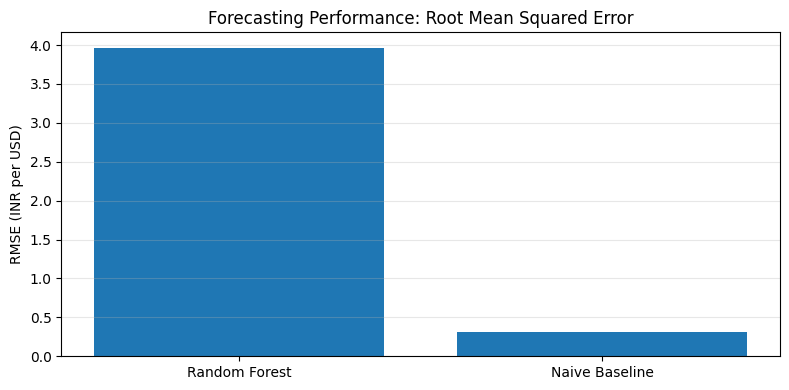

In [14]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Use the corrected one-step-ahead holdout evaluation
comparison = pd.DataFrame({
    "Model": ["Random Forest", "Naive Baseline"],
    "MAE": [
        mean_absolute_error(y_test, rf_predictions),
        mean_absolute_error(y_test, baseline_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, rf_predictions)),
        np.sqrt(mean_squared_error(y_test, baseline_predictions))
    ]
})

print("FINAL HOLDOUT MODEL COMPARISON")
display(comparison.round(4))

# Plot MAE
plt.figure(figsize=(8, 4))
plt.bar(comparison["Model"], comparison["MAE"])
plt.title("Forecasting Performance: Mean Absolute Error")
plt.ylabel("MAE (INR per USD)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Plot RMSE
plt.figure(figsize=(8, 4))
plt.bar(comparison["Model"], comparison["RMSE"])
plt.title("Forecasting Performance: Root Mean Squared Error")
plt.ylabel("RMSE (INR per USD)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



## 8. Conclusion and Limitations

### Key Findings

This project developed a machine learning workflow to forecast the next available USD/INR exchange-rate observation using historical data from the Reserve Bank of India.

The Random Forest Regressor was compared with a naive baseline that predicts the next exchange rate using the latest observed rate. In the chronological holdout evaluation, the naive baseline achieved lower MAE and RMSE than the Random Forest model.

This result illustrates that more complex machine learning models do not necessarily outperform simple forecasting methods. Exchange rates can be difficult to predict because they respond to changing economic conditions, monetary policy, global risk sentiment and unexpected events.

### Limitations

- The model uses historical exchange rates rather than a comprehensive set of economic fundamentals.
- The evaluation covers one chronological holdout period, so performance may differ across other periods.
- The Random Forest model has limited ability to extrapolate trends beyond the values represented in its training data.
- The dataset used in this project ends on 30 June 2026. Forecasts generated from it should not be interpreted as current market quotes.
- The model is an educational forecasting demonstration, not a financial decision-making tool.

### Skills Demonstrated

- Data cleaning and preprocessing with pandas
- Exploratory data analysis and visualisation
- Time-series feature engineering
- Machine learning with scikit-learn
- Chronological train-test evaluation
- Model comparison using MAE and RMSE
- Economic interpretation of forecasting results

### Final Takeaway

The project demonstrates an end-to-end introductory machine learning workflow applied to an economic problem. Its main contribution is the reproducible implementation and honest evaluation of model performance, including the finding that a simple baseline outperformed the more complex model.


In [15]:

from pathlib import Path

rf_mae = comparison.loc[
    comparison["Model"] == "Random Forest", "MAE"
].iloc[0]
base_mae = comparison.loc[
    comparison["Model"] == "Naive Baseline", "MAE"
].iloc[0]
rf_rmse = comparison.loc[
    comparison["Model"] == "Random Forest", "RMSE"
].iloc[0]
base_rmse = comparison.loc[
    comparison["Model"] == "Naive Baseline", "RMSE"
].iloc[0]

readme = f"""# USD/INR Exchange Rate Forecasting Using Machine Learning

## Overview

An undergraduate economics and machine learning project that forecasts the next available USD/INR exchange-rate observation using historical Reserve Bank of India data.

The project demonstrates data cleaning, exploratory analysis, feature engineering, model training, chronological evaluation, and comparison against a simple benchmark.

## Research Question

Can a Random Forest Regressor forecast the next USD/INR observation more accurately than a naive model that predicts no change from the latest observed rate?

## Data

- Source: Reserve Bank of India, Database on Indian Economy (DBIE)
- Dataset: Daily interbank forex rates, USD vis-a-vis INR
- Data used: 8 August 2000 to 30 June 2026
- Target: RBI Reference Rate
- Source link: https://dbie.rbihub.in/statistics?table=financial_markets.r691_daily_interbank_forex_rates_usd_vis_a_vis_inr

## Methods

- Python, pandas and NumPy for data preparation
- Matplotlib for visualisation
- scikit-learn Random Forest Regressor
- Lagged exchange rates and 5- and 20-observation moving averages
- Chronological training and test split
- Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE)

## Holdout Evaluation

| Model | MAE (INR) | RMSE (INR) |
|---|---:|---:|
| Random Forest | {rf_mae:.4f} | {rf_rmse:.4f} |
| Naive baseline | {base_mae:.4f} | {base_rmse:.4f} |

Lower values indicate better performance. In this holdout evaluation, the naive baseline performed better than the Random Forest. The results show why machine learning forecasts should be compared against simple benchmarks.

## How to Run

1. Open the notebook in Google Colab.
2. Download the RBI CSV dataset using the source link above.
3. Upload the CSV when prompted by the notebook.
4. Run the cells in order.
5. Review the forecast plots, evaluation metrics, and limitations.

## Limitations

- The model uses historical exchange rates and does not include macroeconomic fundamentals.
- Results are based on a single chronological holdout period.
- Random Forest has limited ability to extrapolate beyond the training target range.
- The dataset ends on 30 June 2026 and does not provide a current market quote.
- Forecasts are experimental and are not financial advice.

## Skills Demonstrated

Python | Data Cleaning | Exploratory Data Analysis | Feature Engineering | Scikit-learn | Random Forest | Forecast Evaluation | Economic Interpretation

## Author

Undergraduate economics portfolio project.
"""

Path("README.md").write_text(readme, encoding="utf-8")

# Save evaluation metrics alongside the project
comparison.to_csv("model_comparison.csv", index=False)

print("Created README.md")
print("Created model_comparison.csv")

# Download the README to your computer
from google.colab import files
files.download("README.md")


Created README.md
Created model_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


### Interpretation of Model Performance

The naive baseline outperformed the Random Forest model on the chronological holdout test set.

The baseline achieved a mean absolute error (MAE) of 0.2171 INR per USD and a root mean squared error (RMSE) of 0.3074 INR per USD. The Random Forest model recorded an MAE of 2.8030 and an RMSE of 3.9650.

This suggests that the additional complexity of the Random Forest did not improve forecasting accuracy in this evaluation. One likely reason is that tree-based models have limited ability to extrapolate beyond the target values observed during training.

The results demonstrate why machine learning models should be evaluated against simple benchmarks and why performance on unseen data matters more than the apparent sophistication of a model.
